In [1]:
#Importing the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
#Uploading the CSV file
df=pd.read_csv('superstore_sales.csv')
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [3]:
#Check number of rows and columns
df.shape

(10800, 21)

In [4]:
#Check column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
Row ID           10800 non-null object
Order ID         10800 non-null object
Order Date       9994 non-null object
Ship Date        9994 non-null object
Ship Mode        9994 non-null object
Customer ID      9994 non-null object
Customer Name    9994 non-null object
Segment          9994 non-null object
Country          9994 non-null object
City             9994 non-null object
State            9994 non-null object
Postal Code      9983 non-null float64
Region           9994 non-null object
Product ID       9994 non-null object
Category         9994 non-null object
Sub-Category     9994 non-null object
Product Name     9994 non-null object
Sales            9994 non-null float64
Quantity         9994 non-null float64
Discount         9994 non-null float64
Profit           9994 non-null float64
dtypes: float64(5), object(16)
memory usage: 1.1+ MB


In [5]:
#Statistical summary
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [6]:
#Check Duplicate records
print("Duplicate rows:",df.duplicated().sum())

Duplicate rows: 504


In [7]:
#Removing Duplicate records
df=df.drop_duplicates()

In [8]:
#Check number of rows and columns(Updated)
df.shape

(10296, 21)

In [9]:
#Handling missing values
df.isnull().sum()

Row ID             0
Order ID           0
Order Date       302
Ship Date        302
Ship Mode        302
Customer ID      302
Customer Name    302
Segment          302
Country          302
City             302
State            302
Postal Code      313
Region           302
Product ID       302
Category         302
Sub-Category     302
Product Name     302
Sales            302
Quantity         302
Discount         302
Profit           302
dtype: int64

In [10]:
#Fill missing numerical values with median
for col in df.select_dtypes(include='number').columns:
    df[col]=df[col].fillna(df[col].median())
    
#Fill missing categorical values with mode
for col in df.select_dtypes(include='object').columns:
    if df[col].isnull().sum()>0:
        df[col]=df[col].fillna(df[col].mode()[0])
        
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [11]:
#Coverting order date into date format
df['Order Date']=pd.to_datetime(df['Order Date'])
print(df['Order Date'].dtype)

datetime64[ns]


In [12]:
#Extracting year and month from order date
df['Year']=df['Order Date'].dt.year
df['Month']=df['Order Date'].dt.month
df['Year-Month']=df['Order Date'].dt.to_period('M')
df[['Order Date','Year','Month','Year-Month']].head()

,Order Date,Year,Month,Year-Month
0,2017-11-08,2017,11,2017-11
1,2017-11-08,2017,11,2017-11
2,2017-06-12,2017,6,2017-06
3,2016-10-11,2016,10,2016-10
4,2016-10-11,2016,10,2016-10


In [13]:
#Analysis of customer purchase volume
customer_purchase=df.groupby('Customer ID').agg(
   Total_Orders=('Order ID','nunique'),
   Total_Sales=('Sales','sum'),
   Total_Quantity=('Quantity','sum')
).reset_index()
customer_purchase.head()

,Customer ID,Total_Orders,Total_Sales,Total_Quantity
0,AA-10315,5,5563.560,30.0
1,AA-10375,9,1056.390,41.0
2,AA-10480,4,1790.512,36.0
3,AA-10645,6,5086.935,64.0
4,AB-10015,3,886.156,13.0


In [14]:
#Finding the TOp 10 customers by sales
top_customers=customer_purchase.sort_values(by='Total_Sales',ascending=False).head(10)
top_customers

,Customer ID,Total_Orders,Total_Sales,Total_Quantity
700,SM-20320,5,25043.050,50.0
787,WB-21850,312,22616.082,1052.0
741,TC-20980,5,19052.218,42.0
621,RB-19360,6,15117.339,71.0
730,TA-21385,4,14595.620,36.0
6,AB-10105,10,14473.571,73.0
434,KL-16645,12,14175.229,113.0
669,SC-20095,9,14142.334,87.0
327,HL-15040,6,12873.298,50.0
683,SE-20110,11,12209.438,78.0


In [15]:
#Analysis of category-wise sales and profit
category_analysis=df.groupby('Category').agg(
   Total_Sales=('Sales','sum'),
   Total_Profit=('Profit','sum'),
   Total_Quantity=('Quantity','sum')
).reset_index()
category_analysis

,Category,Total_Sales,Total_Profit,Total_Quantity
0,Furniture,741999.7953,18451.2728,8028.0
1,Office Supplies,735503.0120,125108.0838,23812.0
2,Technology,836154.0330,145454.9481,6939.0


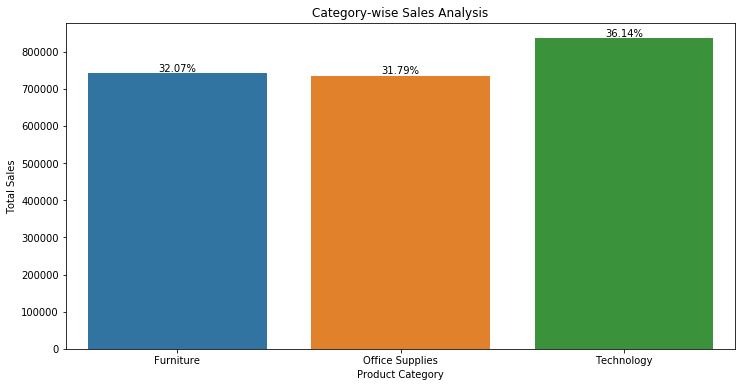

In [16]:
#Creating Category-wise sales chart
plt.figure(figsize=(12,6))
ax=sns.barplot(data=category_analysis,x='Category',y='Total_Sales')
total = category_analysis['Total_Sales'].sum()
for bar in ax.patches:
    percentage=(bar.get_height()/total)*100
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f'{percentage:.2f}%',
        ha='center',
        va='bottom'
    )
plt.title('Category-wise Sales Analysis')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.savefig('Category-wise Sales Analysis.jpg',format="jpg",width=1200,height=600,scale=2)
plt.show()

In [17]:
#Analysis of Region-wise sales and profit
region_analysis=df.groupby('Region').agg(
   Total_Sales=('Sales','sum'),
   Total_Proit=('Profit','sum'),
   Total_Quantity=('Quantity','sum')
).reset_index()
region_analysis

,Region,Total_Sales,Total_Proit,Total_Quantity
0,Central,501239.8908,39706.3625,8780.0
1,East,678781.2400,91522.7800,10618.0
2,South,391721.9050,46749.4303,6209.0
3,West,741913.8045,111035.7319,13172.0


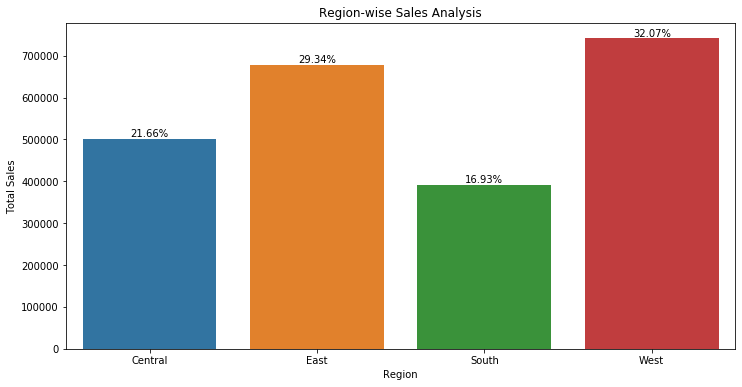

In [18]:
#Creating Region-wise sales chart
plt.figure(figsize=(12,6))
ax=sns.barplot(data=region_analysis,x='Region',y='Total_Sales')
total = category_analysis['Total_Sales'].sum()
for bar in ax.patches:
    percentage=(bar.get_height()/total)*100
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f'{percentage:.2f}%',
        ha='center',
        va='bottom'
    )
plt.title('Region-wise Sales Analysis')
plt.xlabel('Region')
plt.ylabel('Total Sales')
plt.savefig('Region-wise Sales Analysis.jpg',format="jpg",width=1200,height=600,scale=2)
plt.show()

In [19]:
#Analysis of Customer Segment-wise sales and profit
segment_analysis=df.groupby('Segment').agg(
   Total_Sales=('Sales','sum'),
   Total_Profit=('Profit','sum'),
   Total_Quantity=('Quantity','sum')
).reset_index()
segment_analysis

,Segment,Total_Sales,Total_Profit,Total_Quantity
0,Consumer,1.177857e+06,136736.4922,20427.0
1,Corporate,7.061464e+05,91979.1340,11608.0
2,Home Office,4.296531e+05,60298.6785,6744.0


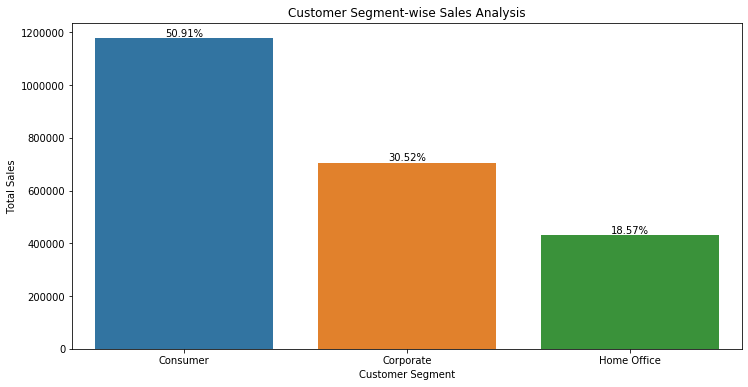

In [20]:
#Creating Customer Segment-wise sales chart
plt.figure(figsize=(12,6))
ax=sns.barplot(data=segment_analysis,x='Segment',y='Total_Sales')
total = category_analysis['Total_Sales'].sum()
for bar in ax.patches:
    percentage=(bar.get_height()/total)*100
    plt.text(
        bar.get_x()+bar.get_width()/2,
        bar.get_height(),
        f'{percentage:.2f}%',
        ha='center',
        va='bottom'
    )
plt.title('Customer Segment-wise Sales Analysis')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.savefig('Customer Segment-wise Sales Analysis.jpg',format="jpg",width=1200,height=600,scale=2)
plt.show()

In [21]:
#Analysis of Monthly sales velocity
monthly_sales=df.groupby('Year-Month')['Sales'].sum().reset_index()
monthly_sales['Year-Month']=monthly_sales['Year-Month'].astype(str)
monthly_sales.head(10)

,Year-Month,Sales
0,2015-01,14236.8950
1,2015-02,4519.8920
2,2015-03,55691.0090
3,2015-04,28295.3450
4,2015-05,23648.2870
5,2015-06,34595.1276
6,2015-07,33946.3930
7,2015-08,27909.4685
8,2015-09,81777.3508
9,2015-10,31453.3930


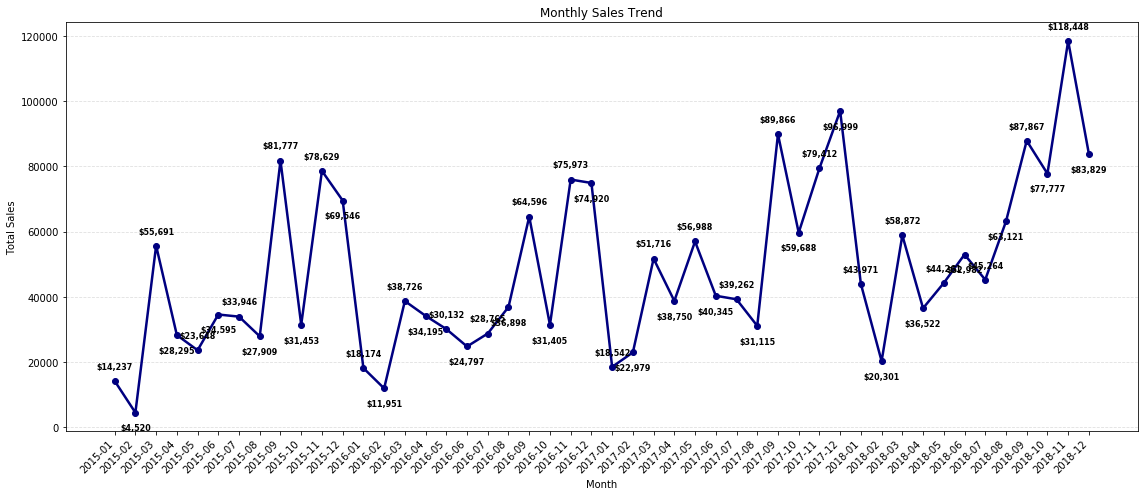

In [22]:
#plotting Monthly sales Graph
plt.figure(figsize=(16, 7))
plt.plot(
    monthly_sales['Year-Month'],
    monthly_sales['Sales'],
    marker='o',
    color='navy',
    linewidth=2.5,
    markersize=6
)

# Display all sales values
for i, (x, y) in enumerate(zip(monthly_sales['Year-Month'], monthly_sales['Sales'])):
    offset = 12 if i % 2 == 0 else -18
    plt.annotate(
        f'${y:,.0f}',
        (x, y),
        textcoords='offset points',
        xytext=(0, offset),
        ha='center',
        fontsize=8,
        fontweight='bold'
    )
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.savefig('Monthly_Sales_Trend.png', dpi=300, bbox_inches='tight')
plt.show()

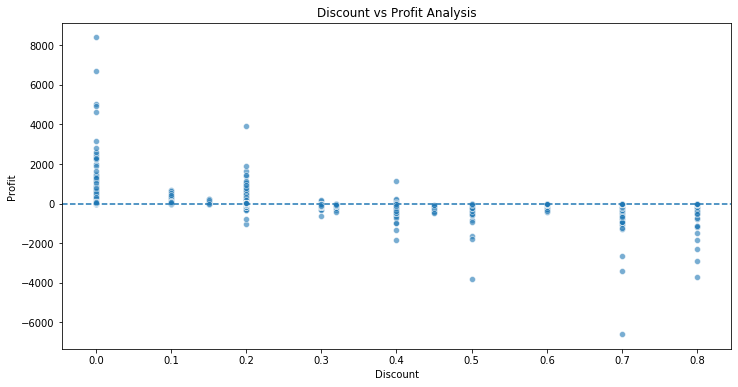

In [23]:
#Plotting Discount versus Profit Analysis Graph
plt.figure(figsize=(12,6))
sns.scatterplot(data=df,x='Discount',y='Profit',alpha=0.6)
plt.title('Discount vs Profit Analysis')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.axhline(0, linestyle='--')
plt.savefig('Discount vs Profit Analysis.jpg',format="jpg",width=1200,height=600,scale=2)
plt.show()

In [24]:
#Calculating the correlation
correlation = df['Discount'].corr(df['Profit'])
print("Discount-Profit Correlation:", correlation)

Discount-Profit Correlation: -0.21984993327941824


# Business Observations & Key Insights

Based on the Superstore Sales Analysis, the following business insights were identified:

### 1. Category Performance
    
Technology generated the highest sales of approximately **\$836,154**, followed by Furniture and Office Supplies. However,      Furniture showed lower profitability compared to the other categories.
    
### 2. Regional Performance
    
The West Region recorded the highest sales of approximately **\$741,914** and the highest profit of **\$111,036**. The East Region generated approximately **\$678,781** in sales.
    
### 3. Customer Segment
    
The Consumer segment contributed the highest sales of approximately **\$1.18** million, followed by Corporate with **$706,146**.  Home Office recorded the lowest sales but achieved the highest profit margin.
    
### 4. Monthly Sales Trends
    
November 2018 recorded the highest monthly sales of **\$118,447.83**, while February 2015 recorded the lowest monthly sales of **\$4,519.89.
    
### 5. Discount vs Profit Analysis
    
The correlation between Discount and Profit was approximately **-0.22**, indicating a negative relationship between discounts and profitabilty.
    
---

# Conclusion

Technology, the West region, and the Consumer segment were the major contributors to sales performance. The business should focus on improving Furniture profitability, controlling discounts, and increasing sales during low-performing months to improve overall business performance.